In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("./CSVs/Churn_Modelling.csv")

In [3]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


In [4]:
df = df.iloc[:,3:]

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  object 
 2   Gender           10000 non-null  object 
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 859.5+ KB


In [6]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [7]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.Exited.value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [10]:
df.Gender.value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [11]:
df.Geography.value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [12]:
df = pd.get_dummies(df,columns=["Geography","Gender"],drop_first=True,dtype="int")

In [13]:
df

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,1,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,1,0,1


In [14]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split

In [15]:
Nor = MinMaxScaler()
Std = StandardScaler()

In [16]:
x_train,x_test,y_train,y_test = train_test_split(df.drop("Exited",axis=1),df.Exited,test_size=.15)

In [17]:
x_train.shape,x_test.shape

((8500, 11), (1500, 11))

In [18]:
x_tr_Nor = Nor.fit_transform(x_train)
x_te_Nor = Nor.transform(x_test)

In [19]:
x_tr_Std = Std.fit_transform(x_train)
x_te_Std = Std.transform(x_test)

In [20]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [60]:
model = Sequential()

model.add(Dense(11,activation="relu",input_dim=11))
model.add(Dense(7,activation="relu"))
model.add(Dense(1,activation="sigmoid"))

C:\Users\Admin\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [61]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 11)                  │             132 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 7)                   │              84 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 1)                   │               8 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 224 (896.00 B)

 Trainable params: 224 (896.00 B)

 Non-trainable params: 0 (0.00 B)

In [62]:
model.compile(loss="binary_crossentropy",optimizer = "Adam",metrics = ["Accuracy"])

In [85]:
%%time
history = model.fit(x_tr_Nor,y_train,epochs = 100,validation_split=0.2)

Epoch 1/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - Accuracy: 0.8534 - loss: 0.3507 - val_Accuracy: 0.8535 - val_loss: 0.3377
Epoch 2/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8528 - loss: 0.3479 - val_Accuracy: 0.8529 - val_loss: 0.3387
Epoch 3/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - Accuracy: 0.8513 - loss: 0.3486 - val_Accuracy: 0.8576 - val_loss: 0.3369
Epoch 4/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8524 - loss: 0.3484 - val_Accuracy: 0.8553 - val_loss: 0.3386
Epoch 5/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8515 - loss: 0.3471 - val_Accuracy: 0.8541 - val_loss: 0.3363
Epoch 6/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8522 - loss: 0.3474 - val_Accuracy: 0.8571 - val_loss: 0.3355
Epoch 7/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8543 - loss: 0.3466 - val_Accuracy: 0.8553 - val_loss: 0.3415
Epoch 8/100
213/213 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - Accuracy: 0.8534 - loss: 0.3466 - val_Ac

In [86]:
#model.layers[1].get_weights()

In [87]:
y_log = model.predict(x_te_Nor)

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [88]:
y_pred = np.where(y_log>0.5,1,0)

In [89]:
y_pred , y_log

(array([[0],
        [0],
        [0],
        ...,
        [1],
        [0],
        [0]], shape=(1500, 1)),
 array([[0.08734021],
        [0.04566193],
        [0.40456322],
        ...,
        [0.9990069 ],
        [0.00337876],
        [0.01086081]], shape=(1500, 1), dtype=float32))

In [90]:
from sklearn.metrics import classification_report

In [91]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1203
           1       0.79      0.45      0.57       297

    accuracy                           0.87      1500
   macro avg       0.83      0.71      0.75      1500
weighted avg       0.86      0.87      0.85      1500



In [92]:
history.history

{'Accuracy': [0.8533823490142822,
  0.8527941107749939,
  0.8513235449790955,
  0.8523529171943665,
  0.8514705896377563,
  0.8522058725357056,
  0.8542646765708923,
  0.8533823490142822,
  0.8547058701515198,
  0.8536764979362488,
  0.8548529148101807,
  0.8547058701515198,
  0.8548529148101807,
  0.857205867767334,
  0.8535293936729431,
  0.8551470637321472,
  0.8550000190734863,
  0.8542646765708923,
  0.856176495552063,
  0.8548529148101807,
  0.8560293912887573,
  0.8573529124259949,
  0.8539705872535706,
  0.8552941083908081,
  0.8548529148101807,
  0.8545588254928589,
  0.8567647337913513,
  0.8580882549285889,
  0.857205867767334,
  0.855441153049469,
  0.8542646765708923,
  0.856176495552063,
  0.8564705848693848,
  0.857205867767334,
  0.8577941060066223,
  0.8545588254928589,
  0.8548529148101807,
  0.8569117784500122,
  0.8569117784500122,
  0.8586764931678772,
  0.855441153049469,
  0.8567647337913513,
  0.8576470613479614,
  0.8582352995872498,
  0.857205867767334,
  0.85

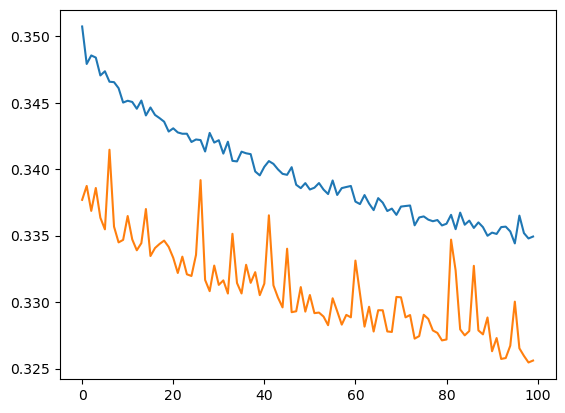

In [93]:
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])


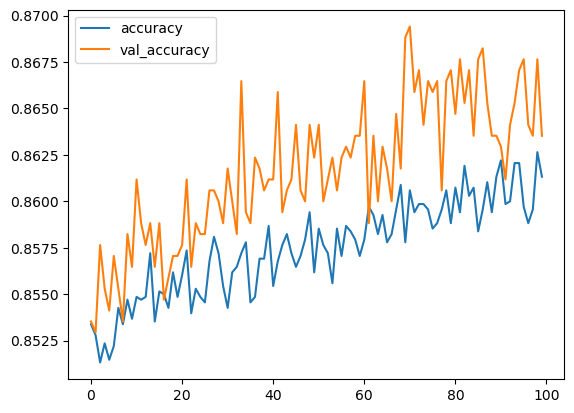

In [99]:
plt.plot(history.history["Accuracy"])
plt.plot(history.history["val_Accuracy"])
plt.legend(["accuracy","val_accuracy"])